<a href="https://colab.research.google.com/github/AbhishekShah272002/Machine-Learning-Study./blob/main/Work/glass_identification_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

In [ ]:
df = pd.read_csv("glass identification.csv")

In [ ]:
df.head()

,Id,RI,Na,Mg,Al,Si,Ka,Ca,Ba,Fe,Type
0,1,1.51763,12.61,3.59,1.31,73.29,0.58,8.5,0.0,0.0,1
1,2,1.51761,12.81,3.54,1.23,73.24,0.58,8.39,0.0,0.0,1
2,3,1.51784,12.68,3.67,1.16,73.11,0.61,8.7,0.0,0.0,1
3,4,1.52196,14.36,3.85,0.89,71.36,0.15,9.15,0.0,0.0,1
4,5,1.51911,13.90,3.73,1.18,72.12,0.06,8.89,0.0,0.0,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Id      200 non-null    int64  
 1   RI      198 non-null    float64
 2   Na      198 non-null    float64
 3   Mg      198 non-null    float64
 4   Al      196 non-null    float64
 5   Si      196 non-null    float64
 6   Ka      200 non-null    float64
 7   Ca      200 non-null    object 
 8   Ba      200 non-null    float64
 9   Fe      200 non-null    float64
 10  Type    200 non-null    int64  
dtypes: float64(8), int64(2), object(1)
memory usage: 17.3+ KB


In [ ]:
df['Ca'] = pd.to_numeric(df['Ca'].astype(str).str.strip(), errors='coerce')
if 'id' in df.columns.str.lower() or df.columns[0].lower() == 'id':
    X = df.iloc[:, 1:-1]
else:
    X = df.iloc[:, :-1]
y = df.iloc[:, -1]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
imputer = SimpleImputer(strategy='mean')
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Cleaned and scaled successfully!")
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Cleaned and scaled successfully!
Training shape: (160, 9)
Testing shape: (40, 9)


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
import numpy as np

param_grid = {'n_neighbors': np.arange(1, 21)}
knn = KNeighborsClassifier()

grid_search = GridSearchCV(knn, param_grid, cv=5, scoring='f1_macro')
grid_search.fit(X_train_scaled, y_train)
best_k = grid_search.best_params_['n_neighbors']
print(f"The best value for K is: {best_k} with a cross-validated macro F1-score of: {grid_search.best_score_:.4f}")


The best value for K is: 1 with a cross-validated macro F1-score of: 0.5838


Final Test Macro F1-Score: 0.6953

Classification Report:
              precision    recall  f1-score   support

           1       0.80      0.73      0.76        11
           2       0.69      0.73      0.71        15
           3       0.50      0.33      0.40         3
           5       0.67      0.67      0.67         3
           6       0.67      1.00      0.80         2
           7       0.83      0.83      0.83         6

    accuracy                           0.72        40
   macro avg       0.69      0.72      0.70        40
weighted avg       0.72      0.72      0.72        40



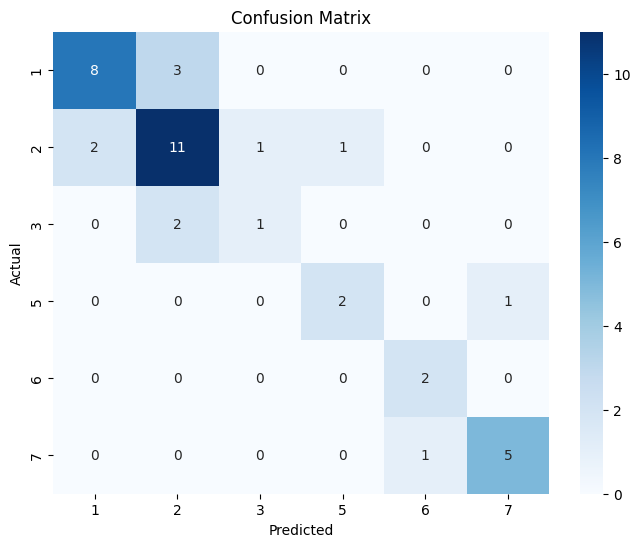

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
final_knn = KNeighborsClassifier(n_neighbors=best_k)
final_knn.fit(X_train_scaled, y_train)
y_pred = final_knn.predict(X_test_scaled)
macro_f1 = f1_score(y_test, y_pred, average='macro')
print(f"Final Test Macro F1-Score: {macro_f1:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()